<a href="https://colab.research.google.com/github/Sbindola/2026_MLEES_book/blob/main/LABS/part-III/6.3-land-cover-classification-exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Notebook-friendly copy of `part-III/6.3-land-cover-classification-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [1]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch", "torchmetrics": "torchmetrics"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# 6.3) (Exercise) Land Cover Classification
![EuroSAT overview image](https://raw.githubusercontent.com/phelber/EuroSAT/master/eurosat_overview_small.jpg)

This notebook is converted from the source: https://www.coursera.org/learn/getting-started-with-tensor-flow2

**🎯 Learning objectives**

- Construct CNNs that classify EuroSAT images into one of 10 land use classes
- Save and load trained models
- Improve the performance of the model

**Land Cover Classification** aims to automatically provide labels describing the represented physical land type or how a land area is used (e.g., residential, industrial).   

**Convolutional Neural Networks (CNNs)**,  the state of-the-art image classification method in computer vision and machine learning, have been reported to be suitable for the classification of remotely sensed
images.

However, the classification of remotely sensed images is a challenging task, particularly due to the lack of reliably labeled ground truth datasets.

The [EuroSAT dataset](https://github.com/phelber/EuroSAT) provides large quantity of training data for this purpose. It consists of 27000 labelled Sentinel-2 satellite images of different land uses: residential, industrial, highway, river, forest, pasture, herbaceous vegetation, annual crop, permanent crop and sea/lake.

For a reference, see the following papers:
- Eurosat: A novel dataset and deep learning benchmark for land use and land cover classification. Patrick Helber, Benjamin Bischke, Andreas Dengel, Damian Borth. IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing, 2019.
- Introducing EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification. Patrick Helber, Benjamin Bischke, Andreas Dengel. 2018 IEEE International Geoscience and Remote Sensing Symposium, 2018.



---




You can **create your own code** by following each question **or complete the code with blanks**.


---

In [2]:
# Run this cell first to import all required packages.
import torch
import torch.nn as nn
from collections import OrderedDict

In [3]:
import torchvision

In [4]:
import torchmetrics
from sklearn.model_selection import train_test_split

In [5]:
import os
import glob
import tarfile
import pooch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# If you would like to make further imports from torch or torchvision, add them here

## Data Setup

Using the EuroSAT dataset which consists of 27000 images and labels might use too much memory, thus we use a smaller subset of the original dataset - 4000 training images and 1000 testing images with roughly equal numbers of each class.

In [6]:
# Run this cell to fetch and reassemble the dataset
chunk_suffixes = ["aa", "ab"]
chunk_hashes = {
    "aa": "ce9f73e68261a010956eeb73876f047f35a25986b037694cd08cc0a837418f3c",
    "ab": "b87e1a0b9da3e69579723103a4934d1b0bbb518d3d1a0d11f51b5ff75db56e25",
}
cache_dir = pooch.os_cache("mlees")
chunk_paths = [
    pooch.retrieve(
        url=f"https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-III/data_cnn.zip.part{suffix}",
        known_hash=f"sha256:{chunk_hashes[suffix]}",
        fname=f"data_cnn.zip.part{suffix}",
        path=cache_dir,
    )
    for suffix in chunk_suffixes
]

In [7]:
data_cnn_archive = os.path.join(cache_dir, "data_cnn.zip")
if not os.path.exists(data_cnn_archive):
    with open(data_cnn_archive, "wb") as out_f:
        for chunk_path in chunk_paths:
            with open(chunk_path, "rb") as in_f:
                out_f.write(in_f.read())
    import zipfile
    with zipfile.ZipFile(data_cnn_archive) as z:
        z.extractall(cache_dir)

In [8]:
data_cnn_dir = os.path.join(cache_dir, "data_cnn")

In [9]:
# Import the Eurosat data
def load_eurosat_data():
    x_train = np.load(os.path.join(data_cnn_dir, 'x_train.npy'))
    y_train = np.load(os.path.join(data_cnn_dir, 'y_train.npy'))
    x_val  = np.load(os.path.join(data_cnn_dir, 'x_test.npy'))
    y_val  = np.load(os.path.join(data_cnn_dir, 'y_test.npy'))
    return (x_train, y_train), (x_val, y_val)

In [10]:
(X_train, y_train), (X_val_test, y_val_test) = load_eurosat_data()
X_val, X_test, y_val, y_test = train_test_split(X_val_test, y_val_test, test_size=0.5, random_state=42)

In [11]:
# Normalize data, move the channel dimension to PyTorch's expected position
# (channels first), and convert everything to tensors
def to_tensor(X, y):
    X = torch.tensor(X / 255.0, dtype=torch.float32).permute(0, 3, 1, 2)
    y = torch.tensor(y, dtype=torch.long).reshape(-1)  # (N, 1) -> (N,)
    return X, y

In [12]:
X_train, y_train = to_tensor(X_train, y_train)
X_val, y_val = to_tensor(X_val, y_val)
X_test, y_test = to_tensor(X_test, y_test)

Since PyTorch has no `.compile()`/`.fit()`/`.evaluate()`, we'll define three small reusable helpers before building any models — one to train a model for a number of epochs (optionally with callbacks and a validation set), one to evaluate a model on a dataset, and a `History` class that mimics Keras's `history.history` dict-of-lists so the rest of this notebook can stay close to the original.

In [13]:
class History:
    def __init__(self):
        self.history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}

In [14]:
def evaluate_model(model, X, y, batch_size=32):
    model.eval()
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, y), batch_size=batch_size)
    losses = []
    accuracy.reset()
    with torch.no_grad():
        for X_batch, y_batch in loader:
            y_pred = model(X_batch)
            losses.append(loss_fn(y_pred, y_batch).item())
            accuracy.update(y_pred, y_batch)
    return [np.mean(losses), accuracy.compute().item()]

In [15]:
def train_model(model, X, y, epochs, validation_data=None, callbacks=None, verbose=1):
    callbacks = callbacks or []
    optimizer = optimizer_class(model.parameters())
    history = History()
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, y), batch_size=32, shuffle=True)

    for epoch in range(epochs):
        model.train()
        train_losses = []
        accuracy.reset()
        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())
            accuracy.update(y_pred, y_batch)

        logs = {"loss": np.mean(train_losses), "accuracy": accuracy.compute().item()}
        history.history["loss"].append(logs["loss"])
        history.history["accuracy"].append(logs["accuracy"])

        report = f"Epoch {epoch + 1}/{epochs} - loss: {logs['loss']:.4f} - accuracy: {logs['accuracy']:.4f}"
        if validation_data is not None:
            val_loss, val_accuracy = evaluate_model(model, *validation_data)
            logs["val_loss"], logs["val_accuracy"] = val_loss, val_accuracy
            history.history["val_loss"].append(val_loss)
            history.history["val_accuracy"].append(val_accuracy)
            report += f" - val_loss: {val_loss:.4f} - val_accuracy: {val_accuracy:.4f}"
        if verbose:
            print(report)

        stop_training = False
        for callback in callbacks:
            if callback.on_epoch_end(epoch, model, logs) == "stop":
                stop_training = True
        if stop_training:
            break

    return history

## Q1 Build a CNN `model1` to classify Eurosat data.

Let's construct a CNN called `model1` using `nn.Sequential`, according to the following specifications:

* The first layer should be a `Conv2d` layer with 16 filters, a 3x3 kernel size, and 'same' padding. Name this layer 'conv_1'.
* Follow it with a `ReLU` activation, named 'relu_1'.
* The third layer should also be a `Conv2d` layer with 8 filters, a 3x3 kernel size, and 'same' padding. Name this layer 'conv_2'.
* Follow it with a `ReLU` activation, named 'relu_2'.
* The fifth layer should be a `MaxPool2d` layer with a pooling window size of 8x8. Name this layer 'pool_1'.
* The sixth layer should be a `Flatten` layer, named 'flatten'.
* The seventh layer should be a `Linear` layer with 32 units, followed by a `ReLU` activation. Name these layers 'dense_1' and 'relu_3'.
* The final layer should be a `Linear` layer with 10 units and no activation (unlike Keras, `nn.CrossEntropyLoss` expects raw logits, not softmax probabilities). Name this layer 'dense_2'.

*Hint 1: Unlike `keras.models.Sequential`, `nn.Sequential` doesn't have an `.add()` method — but if you pass it an [`OrderedDict`](https://docs.python.org/3/library/collections.html#collections.OrderedDict) of `(name, layer)` pairs, you get the same named-layer access (`model1.conv_1`, etc.) that Keras's `name=` argument gives you.*

*Hint 2: `nn.Conv2d` needs an explicit number of input channels — 3 for the first layer (RGB), and `conv_2`'s input channels equal `conv_1`'s output channels.*

*Hint 3: As in the artificial-neural-networks and deep-computer-vision exercises, [`nn.LazyLinear`](https://docs.pytorch.org/docs/stable/generated/torch.nn.LazyLinear.html) can save you from computing the flattened size by hand.*

In [18]:
# Assign value to input_shape variable (channels, height, width)
input_shape = X_train.shape[1:]

torch.Size([3, 64, 64])

In [19]:
# Build the model, one named layer at a time
model1 = nn.Sequential(OrderedDict([
    ("conv_1", nn.Conv2d(3, 16, kernel_size=3, padding="same")),
    ("relu_1", nn.ReLU()),
    ("conv_2", nn.Conv2d(16, 8, kernel_size=3, padding="same")),
    ("relu_2", nn.ReLU()),
    ("pool_1", nn.MaxPool2d((8, 8))),
    ("flatten", nn.Flatten()),
    ("dense_1", nn.LazyLinear(32)),
    ("relu_3", nn.ReLU()),
    ("dense_2", nn.LazyLinear(10)),
]))

In [20]:
# Run one batch through the model to materialize the LazyLinear layers
model1(X_train[:1])

tensor([[ 0.1794, -0.1777,  0.0315, -0.0222, -0.0982,  0.0924,  0.1119,  0.0840,
         -0.1233,  0.1360]], grad_fn=<AddmmBackward0>)

❓❓❓ Do you have a model of the following structure?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model1-summary-reference.jpg?raw=1'> </center>

*(This screenshot is from the original Keras version of this exercise — `print(model1)` will show a differently formatted, but structurally equivalent, layer list.)*

## Q2 Set up `model1`'s loss function, optimizer, and an evaluation metric.

* Use the Adam optimiser, cross entropy loss function, and a single accuracy metric.

In [21]:
loss_fn = nn.CrossEntropyLoss() # Set the loss function
optimizer_class = torch.optim.Adam # Set the optimizer class (train_model binds it to each model's parameters)
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=10) # Set the evaluation metric

## Q3 Evaluate the initial accuracy of `model1`: Is the initial accuracy of the model as you have expected?

In [22]:
# Calculate its initialised test accuracy
test_loss, test_acc = evaluate_model(model1, X_test, y_test)
print('Test accuracy: {acc:0.3f}'.format(acc=test_acc))

Test accuracy: 0.070


❓❓❓ Does your model have a similar initial accuracy & why?

Perché il modello non è ancora stato addestrato.

I pesi della rete neurale sono inizializzati in modo del tutto casuale. Di conseguenza, il modello sta effettuando delle predizioni casuali. Poiché il dataset EuroSAT ha 10 classi distinte bilanciate, la probabilità di indovinare a caso la classe corretta è di circa il 10% (1 su 10).

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-initial-accuracy-reference.jpg?raw=1'> </center>

## Q4 Train `model1` with 15 epochs, store the result in variable 'history';
* Store the fitting result in a variable history;

In [23]:
epochs = 15

history = train_model(model1, X_train, y_train,
                    epochs=epochs,
                    validation_data=(X_val, y_val))

Epoch 1/15 - loss: 1.9790 - accuracy: 0.2323 - val_loss: 1.8451 - val_accuracy: 0.2520
Epoch 2/15 - loss: 1.7310 - accuracy: 0.3155 - val_loss: 1.7333 - val_accuracy: 0.2920
Epoch 3/15 - loss: 1.6555 - accuracy: 0.3413 - val_loss: 1.6866 - val_accuracy: 0.3300
Epoch 4/15 - loss: 1.6070 - accuracy: 0.3762 - val_loss: 1.6517 - val_accuracy: 0.3320
Epoch 5/15 - loss: 1.5255 - accuracy: 0.4078 - val_loss: 1.5443 - val_accuracy: 0.4020
Epoch 6/15 - loss: 1.4063 - accuracy: 0.4697 - val_loss: 1.4134 - val_accuracy: 0.4400
Epoch 7/15 - loss: 1.3261 - accuracy: 0.4978 - val_loss: 1.3666 - val_accuracy: 0.4700
Epoch 8/15 - loss: 1.2591 - accuracy: 0.5260 - val_loss: 1.2989 - val_accuracy: 0.4620
Epoch 9/15 - loss: 1.2024 - accuracy: 0.5418 - val_loss: 1.2894 - val_accuracy: 0.5040
Epoch 10/15 - loss: 1.1571 - accuracy: 0.5655 - val_loss: 1.2111 - val_accuracy: 0.5240
Epoch 11/15 - loss: 1.1186 - accuracy: 0.5853 - val_loss: 1.1939 - val_accuracy: 0.5220
Epoch 12/15 - loss: 1.0718 - accuracy: 0.

❓❓❓ Do you have similar print output?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-training-output-reference.jpg?raw=1'> </center>

*(Again, expect a differently formatted but comparable progress report — there's no Keras-style progress bar here.)*

## Q5 Evaluate the accuracy of fitted `model1`, plot training, validation set loss and accuracy, and print the model's structure

* Evaluate the fitted model
    * What's the test accuracy after training the model? Does it improve from the initialization?
* Print the model's structure

In [24]:
# Calculate the test accuracy
score = evaluate_model(model1, X_test, y_test)
print('Test accuracy: {acc:0.3f}'.format(acc=score[1]))

Test accuracy: 0.622


❓❓❓ Do you have similar test accuracy?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-test-accuracy-reference.jpg?raw=1'> </center>

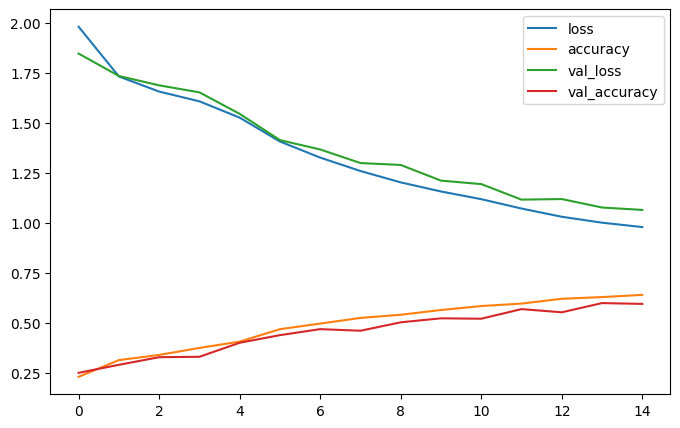

In [25]:
# Plot training, validation set loss and accuracy
pd.DataFrame(history.history).plot(figsize=(8,5))
plt.show()

❓❓❓ Do you have a similar plot?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-loss-accuracy-plot-reference.png?raw=1'> </center>

In [26]:
# Print the model's structure
print(model1)

Sequential(
  (conv_1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (relu_1): ReLU()
  (conv_2): Conv2d(16, 8, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (relu_2): ReLU()
  (pool_1): MaxPool2d(kernel_size=(8, 8), stride=(8, 8), padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (dense_1): Linear(in_features=512, out_features=32, bias=True)
  (relu_3): ReLU()
  (dense_2): Linear(in_features=32, out_features=10, bias=True)
)


❓❓❓ Do you have a similar structure?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model-plot-reference.jpg?raw=1'> </center>

*(This reference was generated with Keras's `plot_model` utility, which has no PyTorch equivalent — `print(model)` gives you the same layer-by-layer information as text instead of a diagram.)*

## Q6 Create two callbacks to save the model weights at each epoch and the best validation accuracy epoch

1. `checkpoint_every_epoch`: a callback that saves the model weights every epoch during training;
2. `checkpoint_best_only`: a callback that saves only the weights with the highest validation accuracy.

*Hint 1: Since `train_model` calls each callback's `on_epoch_end(epoch, model, logs)` method after every epoch, a callback here is just a small class with that one method — `logs` is the same dict of `"loss"`/`"accuracy"`/`"val_loss"`/`"val_accuracy"` values printed for that epoch.*

*Hint 2: Use [`torch.save(model.state_dict(), path)`](https://docs.pytorch.org/docs/stable/generated/torch.save.html) to save weights — there's no PyTorch equivalent of Keras's `ModelCheckpoint`, so both callbacks save with plain `torch.save()`.*

In [27]:
# A callback that saves the model weights at the end of every epoch, into a
# directory called 'checkpoints_every_epoch', with filenames like
# 'checkpoint_000.pt', 'checkpoint_001.pt', etc. (the epoch number, formatted
# to three digits)
class CheckpointEveryEpoch:
    def __init__(self, dirpath):
        self.dirpath = dirpath
        os.makedirs(dirpath, exist_ok=True)

    def on_epoch_end(self, epoch, model, logs):
        path = os.path.join(self.dirpath, f"checkpoint_{epoch:03d}.pt")
        torch.save(model.state_dict(), path)

checkpoint_every_epoch = CheckpointEveryEpoch(dirpath="checkpoints_every_epoch")

In [28]:
# A callback that saves the model weights only when they reach the highest
# validation accuracy so far, into a file called
# 'checkpoints_best_only/checkpoint.pt'
class CheckpointBestOnly:
    def __init__(self, filepath, monitor="val_accuracy"):
        self.filepath = filepath
        self.monitor = monitor
        self.best = -np.inf
        os.makedirs(os.path.dirname(filepath), exist_ok=True)

    def on_epoch_end(self, epoch, model, logs):
        if logs[self.monitor] > self.best:
            self.best = logs[self.monitor]
            torch.save(model.state_dict(), self.filepath)

In [29]:
checkpoint_best_only = CheckpointBestOnly(filepath=os.path.join("checkpoints_best_only", "checkpoint.pt"),
                                          monitor="val_accuracy")

## Q7 Build a CNN `model` with the same initial structure as `model1` and train for 15 epochs using the callbacks from Q6

Now, you will train the model using the two callbacks you created. If you created the callbacks correctly, two things should happen:
- At the end of every epoch, the model weights are saved into a directory called `checkpoints_every_epoch`
- At the end of every epoch, the model weights are saved into a directory called `checkpoints_best_only` **only** if those weights lead to the highest validation accuracy

You should then have two directories:
- A directory called `checkpoints_every_epoch` containing filenames that include `checkpoint_000.pt`, `checkpoint_001.pt`, etc, with the numbers corresponding to the epoch
- A directory called `checkpoints_best_only` containing a single `checkpoint.pt` file, containing only the weights leading to the highest validation accuracy

In [30]:
# Create a model with the same initial structure as model1 again from scratch
model = nn.Sequential(OrderedDict([
    ("conv_1", nn.Conv2d(3, 16, kernel_size=3, padding="same")),
    ("relu_1", nn.ReLU()),
    ("conv_2", nn.Conv2d(16, 8, kernel_size=3, padding="same")),
    ("relu_2", nn.ReLU()),
    ("pool_1", nn.MaxPool2d((8, 8))),
    ("flatten", nn.Flatten()),
    ("dense_1", nn.LazyLinear(32)),
    ("relu_3", nn.ReLU()),
    ("dense_2", nn.LazyLinear(10)),
]))
model(X_train[:1])

tensor([[-0.1235,  0.0157,  0.0616,  0.0864,  0.0060,  0.0865, -0.0093,  0.1344,
          0.1787, -0.0179]], grad_fn=<AddmmBackward0>)

In [31]:
# Train model using the callbacks you just created with 15 epochs

callbacks = [checkpoint_every_epoch, checkpoint_best_only]
history = train_model(model, X_train, y_train, epochs=15, validation_data=(X_val, y_val), callbacks=callbacks)

Epoch 1/15 - loss: 2.1348 - accuracy: 0.1780 - val_loss: 1.8570 - val_accuracy: 0.2800
Epoch 2/15 - loss: 1.7349 - accuracy: 0.3185 - val_loss: 1.7914 - val_accuracy: 0.2800
Epoch 3/15 - loss: 1.6801 - accuracy: 0.3260 - val_loss: 1.7160 - val_accuracy: 0.3120
Epoch 4/15 - loss: 1.6170 - accuracy: 0.3613 - val_loss: 1.6547 - val_accuracy: 0.3520
Epoch 5/15 - loss: 1.5604 - accuracy: 0.3815 - val_loss: 1.5836 - val_accuracy: 0.3400
Epoch 6/15 - loss: 1.4727 - accuracy: 0.4317 - val_loss: 1.4850 - val_accuracy: 0.3840
Epoch 7/15 - loss: 1.4066 - accuracy: 0.4507 - val_loss: 1.4197 - val_accuracy: 0.3960
Epoch 8/15 - loss: 1.3742 - accuracy: 0.4582 - val_loss: 1.3791 - val_accuracy: 0.4280
Epoch 9/15 - loss: 1.3140 - accuracy: 0.4848 - val_loss: 1.3435 - val_accuracy: 0.4500
Epoch 10/15 - loss: 1.2658 - accuracy: 0.5163 - val_loss: 1.3564 - val_accuracy: 0.4740
Epoch 11/15 - loss: 1.2421 - accuracy: 0.5207 - val_loss: 1.3102 - val_accuracy: 0.5040
Epoch 12/15 - loss: 1.1900 - accuracy: 0.

❓❓❓ Do you have similar print output?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-checkpoint-training-output-reference.jpg?raw=1'> </center>

## Q8 Create new models `model_last_epoch` and `model_best_epoch` with model1's initial structure; load weights from the latest saved epoch and the saved epoch with the highest validation accuracy respectively

Now you will use the weights you just saved in a fresh model. You should load into two freshly instantiated model instances:
- `model_last_epoch` should contain the weights from the latest saved epoch
- `model_best_epoch` should contain the weights from the saved epoch with the highest validation accuracy

*Hint: `glob.glob("checkpoints_every_epoch/*.pt")` gives you every saved checkpoint path; sorting that list gives you the latest one at the end (since the filenames are zero-padded).*

In [32]:
# Create a new CNN with same structure as model1
model_last_epoch = nn.Sequential(OrderedDict([
    ("conv_1", nn.Conv2d(3, 16, kernel_size=3, padding="same")),
    ("relu_1", nn.ReLU()),
    ("conv_2", nn.Conv2d(16, 8, kernel_size=3, padding="same")),
    ("relu_2", nn.ReLU()),
    ("pool_1", nn.MaxPool2d((8, 8))),
    ("flatten", nn.Flatten()),
    ("dense_1", nn.LazyLinear(32)),
    ("relu_3", nn.ReLU()),
    ("dense_2", nn.LazyLinear(10)),
]))
_ = model_last_epoch(X_train[:1])

In [33]:
# Load the weights from the last training epoch.
latest_checkpoint = sorted(glob.glob("checkpoints_every_epoch/*.pt"))[-1]
model_last_epoch.load_state_dict(torch.load(latest_checkpoint, weights_only=True))

<All keys matched successfully>

In [34]:
# Create a new CNN with same structure as model1
model_best_epoch = nn.Sequential(OrderedDict([
    ("conv_1", nn.Conv2d(3, 16, kernel_size=3, padding="same")),
    ("relu_1", nn.ReLU()),
    ("conv_2", nn.Conv2d(16, 8, kernel_size=3, padding="same")),
    ("relu_2", nn.ReLU()),
    ("pool_1", nn.MaxPool2d((8, 8))),
    ("flatten", nn.Flatten()),
    ("dense_1", nn.LazyLinear(32)),
    ("relu_3", nn.ReLU()),
    ("dense_2", nn.LazyLinear(10)),
]))
model_best_epoch(X_train[:1])

tensor([[-0.0696,  0.0393, -0.0191, -0.1312, -0.1841, -0.0688, -0.1032,  0.0098,
          0.0430, -0.0626]], grad_fn=<AddmmBackward0>)

In [35]:
# Load the weights leading to the highest validation accuracy.
model_best_epoch.load_state_dict(torch.load("checkpoints_best_only/checkpoint.pt", weights_only=True))

<All keys matched successfully>

In [36]:
# Verify the validation accuracy of the last and the best model.

score = evaluate_model(model_last_epoch, X_val, y_val)
print('Model validation accuracy with last epoch weights: {acc:0.3f}'.format(acc=score[1]))
print('')

score = evaluate_model(model_best_epoch, X_val, y_val)
print('Model validation accuracy with best epoch weights: {acc:0.3f}'.format(acc=score[1]))

Model validation accuracy with last epoch weights: 0.544

Model validation accuracy with best epoch weights: 0.544


❓❓❓ Are the saved models' validation accuracy as expected?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-checkpoint-accuracy-reference.jpg?raw=1'> </center>

## Q9 Explore to improve the model performance by trying to reduce the bias: design and train a model2
* For example, train a CNN called model2, which has the same structure as model1, but with more convolution units: `conv_1` has 32 units, `conv_2` has 64 units, `dense_1` with 256 units

❓❓❓
* Does the model performance improve?
* What are other potential strategies to improve model performance by reducing the bias?

In [37]:
# Build model2 with the same structure as model1, but change the number of
# filters in conv_1 to 32 and conv_2 to 64, and dense_1 to 256 units.
model2 = nn.Sequential(OrderedDict([
    ("conv_1", nn.Conv2d(3, 32, kernel_size=3, padding="same")),
    ("relu_1", nn.ReLU()),
    ("conv_2", nn.Conv2d(32, 64, kernel_size=3, padding="same")),
    ("relu_2", nn.ReLU()),
    ("pool_1", nn.MaxPool2d((8, 8))),
    ("flatten", nn.Flatten()),
    ("dense_1", nn.LazyLinear(256)),
    ("relu_3", nn.ReLU()),
    ("dense_2", nn.LazyLinear(10)),
]))
_ = model2(X_train[:1])

In [38]:
# Train the model and store the results in a variable called history
history = train_model(model2, X_train, y_train, epochs=15, validation_data=(X_val, y_val))

Epoch 1/15 - loss: 1.6172 - accuracy: 0.3652 - val_loss: 1.2711 - val_accuracy: 0.5140
Epoch 2/15 - loss: 1.1546 - accuracy: 0.5677 - val_loss: 1.0248 - val_accuracy: 0.6220
Epoch 3/15 - loss: 0.9149 - accuracy: 0.6678 - val_loss: 0.8584 - val_accuracy: 0.6860
Epoch 4/15 - loss: 0.7781 - accuracy: 0.7210 - val_loss: 0.7909 - val_accuracy: 0.7100
Epoch 5/15 - loss: 0.6784 - accuracy: 0.7558 - val_loss: 0.6898 - val_accuracy: 0.7400
Epoch 6/15 - loss: 0.6132 - accuracy: 0.7800 - val_loss: 0.6618 - val_accuracy: 0.7500
Epoch 7/15 - loss: 0.5346 - accuracy: 0.8087 - val_loss: 0.5698 - val_accuracy: 0.7960
Epoch 8/15 - loss: 0.4676 - accuracy: 0.8320 - val_loss: 0.5816 - val_accuracy: 0.7700
Epoch 9/15 - loss: 0.4181 - accuracy: 0.8528 - val_loss: 0.6102 - val_accuracy: 0.7700
Epoch 10/15 - loss: 0.4193 - accuracy: 0.8537 - val_loss: 0.5131 - val_accuracy: 0.8060
Epoch 11/15 - loss: 0.3791 - accuracy: 0.8618 - val_loss: 0.5688 - val_accuracy: 0.8080
Epoch 12/15 - loss: 0.3103 - accuracy: 0.

❓❓❓ Are your printed output similar to the following screenshot?

**Riduzione del Bias** (Sotto-apprendimento / Underfitting): model1 era una rete molto semplice e piccola. Aumentando il numero di filtri (da 16 a 32 nel primo strato e da 8 a 64 nel secondo) e i neuroni nel livello denso (da 32 a 256), abbiamo dato al modello una maggiore capacità espressiva. Questo gli permette di estrarre e memorizzare caratteristiche visive molto più complesse e dettagliate (texture, forme geometriche dei campi, pattern urbani, ecc.).

**Migliore estrazione delle feature**: I canali aggiuntivi nei livelli convoluzionali permettono di combinare e apprendere una varietà molto più ricca di filtri grafici.

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model2-training-output-reference.jpg?raw=1'> </center>

In [39]:
# Calculate the test accuracy
score = evaluate_model(model2, X_test, y_test)
print('Test accuracy: {acc:0.3f}'.format(acc=score[1]))

Test accuracy: 0.798


❓❓❓ Does your model's test accuracy improve and why?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model2-test-accuracy-reference.jpg?raw=1'> </center>

## Q10 Explore to improve the model performance by trying to reduce the variance: design and train a `model3`
* For example, train a CNN called `model3`, which has the same structure as `model2`, add dropout layers one after the max pooling layer, one before the final dense layer with dropout rate of 0.2.

❓❓❓
* Does the model performance improve?
* What are other potential strategies to improve model performance by reducing the variance?

In [40]:
# Build model3 with the same structure as model2, but add two dropout layers -
# one after the max pooling layer, one before the final dense layer.
model3 = nn.Sequential(OrderedDict([
    ("conv_1", nn.Conv2d(3, 32, kernel_size=3, padding="same")),
    ("relu_1", nn.ReLU()),
    ("conv_2", nn.Conv2d(32, 64, kernel_size=3, padding="same")),
    ("relu_2", nn.ReLU()),
    ("pool_1", nn.MaxPool2d((8, 8))),
    ("dropout_1", nn.Dropout(0.2)),
    ("flatten", nn.Flatten()),
    ("dense_1", nn.LazyLinear(256)),
    ("relu_3", nn.ReLU()),
    ("dropout_2", nn.Dropout(0.2)),
    ("dense_2", nn.LazyLinear(10)),
]))
model3(X_train[:1])

tensor([[ 0.0691,  0.0393,  0.0186,  0.0193, -0.0020,  0.0843,  0.0147, -0.0280,
         -0.0266,  0.1002]], grad_fn=<AddmmBackward0>)

In [41]:
# Train the model and store the results in a variable called history
history = train_model(model3, X_train, y_train, epochs=15, validation_data=(X_val, y_val))

Epoch 1/15 - loss: 1.6762 - accuracy: 0.3543 - val_loss: 1.3046 - val_accuracy: 0.5240
Epoch 2/15 - loss: 1.2389 - accuracy: 0.5293 - val_loss: 1.1032 - val_accuracy: 0.6000
Epoch 3/15 - loss: 0.9994 - accuracy: 0.6275 - val_loss: 0.9289 - val_accuracy: 0.6460
Epoch 4/15 - loss: 0.9022 - accuracy: 0.6678 - val_loss: 0.8073 - val_accuracy: 0.7180
Epoch 5/15 - loss: 0.8083 - accuracy: 0.7132 - val_loss: 0.7661 - val_accuracy: 0.7480
Epoch 6/15 - loss: 0.7578 - accuracy: 0.7293 - val_loss: 0.6882 - val_accuracy: 0.7420
Epoch 7/15 - loss: 0.6747 - accuracy: 0.7585 - val_loss: 0.8564 - val_accuracy: 0.6880
Epoch 8/15 - loss: 0.6450 - accuracy: 0.7715 - val_loss: 0.6996 - val_accuracy: 0.7320
Epoch 9/15 - loss: 0.5637 - accuracy: 0.7952 - val_loss: 0.6294 - val_accuracy: 0.7720
Epoch 10/15 - loss: 0.5265 - accuracy: 0.8138 - val_loss: 0.5434 - val_accuracy: 0.7920
Epoch 11/15 - loss: 0.4794 - accuracy: 0.8295 - val_loss: 0.6543 - val_accuracy: 0.7580
Epoch 12/15 - loss: 0.4566 - accuracy: 0.

❓❓❓ Are your printed output similar to the following screenshot?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model3-training-output-reference.jpg?raw=1'> </center>

In [42]:
# Calculate the test accuracy
score = evaluate_model(model3, X_test, y_test)
print('Test accuracy: {acc:0.3f}'.format(acc=score[1]))

Test accuracy: 0.818


❓❓❓ Does your model's test accuracy improve and why?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model3-test-accuracy-reference.jpg?raw=1'> </center>

## Q11 Explore to improve the model performance using transfer learning from a pretrained model

* Use a pretrained [VGG16](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.vgg16.html) model from TorchVision.

    * Does the model performance improve after the above explorations?
    * How would you further improve the model performance?

*Hint 1: `torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.DEFAULT).features` gives you just VGG16's convolutional layers (no classifier head) — the PyTorch equivalent of Keras's `include_top=False`.*

*Hint 2: Freeze every parameter in the pretrained feature extractor with `param.requires_grad = False`, so training only updates the new layers you add on top.*

In [43]:
conv_base = torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.DEFAULT).features
# freeze the weights
for param in conv_base.parameters():
    param.requires_grad = False

model4 = nn.Sequential(OrderedDict([
    ("features", conv_base),
    ("flatten", nn.Flatten()),
    ("dropout_1", nn.Dropout(0.2)),
    ("dense_1", nn.LazyLinear(256)),
    ("relu_1", nn.ReLU()),
    ("dropout_2", nn.Dropout(0.2)),
    ("dense_2", nn.LazyLinear(10)),
]))
model4(X_train[:1])

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:08<00:00, 67.4MB/s]


tensor([[ 0.0371, -0.1662,  0.0757, -0.1127, -0.0249,  0.1161, -0.2774,  0.1363,
         -0.2044, -0.1502]], grad_fn=<AddmmBackward0>)

In [44]:
# Train the model and store the results in a variable called history
history = train_model(model4, X_train, y_train, epochs=15, validation_data=(X_val, y_val))

Epoch 1/15 - loss: 0.7581 - accuracy: 0.7477 - val_loss: 0.3897 - val_accuracy: 0.8700
Epoch 2/15 - loss: 0.3920 - accuracy: 0.8668 - val_loss: 0.3617 - val_accuracy: 0.8700
Epoch 3/15 - loss: 0.3140 - accuracy: 0.8915 - val_loss: 0.3659 - val_accuracy: 0.8820
Epoch 4/15 - loss: 0.2587 - accuracy: 0.9120 - val_loss: 0.3173 - val_accuracy: 0.8920
Epoch 5/15 - loss: 0.2272 - accuracy: 0.9218 - val_loss: 0.3447 - val_accuracy: 0.8940
Epoch 6/15 - loss: 0.1909 - accuracy: 0.9323 - val_loss: 0.3487 - val_accuracy: 0.8940
Epoch 7/15 - loss: 0.1772 - accuracy: 0.9365 - val_loss: 0.3788 - val_accuracy: 0.8780
Epoch 8/15 - loss: 0.1550 - accuracy: 0.9452 - val_loss: 0.3892 - val_accuracy: 0.8900
Epoch 9/15 - loss: 0.1415 - accuracy: 0.9515 - val_loss: 0.4038 - val_accuracy: 0.8840
Epoch 10/15 - loss: 0.1348 - accuracy: 0.9553 - val_loss: 0.3891 - val_accuracy: 0.8880
Epoch 11/15 - loss: 0.1164 - accuracy: 0.9630 - val_loss: 0.4183 - val_accuracy: 0.8820
Epoch 12/15 - loss: 0.1158 - accuracy: 0.

❓❓❓ Are your printed output similar to the following screenshot? It takes a really long time to train ...

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model4-training-output-reference.jpg?raw=1'> </center>

In [45]:
# Calculate the test accuracy
score = evaluate_model(model4, X_test, y_test)
print('Test accuracy: {acc:0.3f}'.format(acc=score[1]))

Test accuracy: 0.858


✌✌✌ Congratulations! You have completed this exercise. Now you know how to train CNNs to classify remote sensing images.

Still, the accuracy reported from the Eurosat dataset paper - Eurosat: A novel dataset and deep learning benchmark for land use and land cover classification is 98.57%. ⚡⚡⚡Have you found strategies to improve the performance to that level?